# 06 · Optimización de hiperparámetros

Hasta aquí el proyecto tiene el EDA (01 y 02), las variables (03), el experimento baseline con Salamandra y el piso clásico (04) y la importancia de variables (05). Este cuaderno sigue en el sprint: busca los hiperparámetros del baseline clásico y mira si cambian algo.

Se optimiza el baseline clásico (TF-IDF y el modelo de 24 variables, ambos con regresión logística) porque es el piso contra el que se compara al LLM, y conviene que tenga una configuración razonable y no la primera que se probó. El LLM no se optimiza: Salamandra-7B-Instruct no se entrena y decodifica de forma determinista, así que no hay nada que ajustar en ese sentido. Su configuración queda fija y se explica en la sección 6.

Para no contaminar la evaluación, la búsqueda se hace con validación cruzada dentro de train. Dev (2.465 tuits) se mide una sola vez al final, con la configuración ya elegida. Todo se recalcula aquí con CPU y la búsqueda tarda unos 3 a 4 minutos.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
for sub in ("experimento", "features", "eda"):
    sys.path.insert(0, str(RAIZ / "scripts" / sub))
import optimizar_hiperparametros as H

pd.set_option("display.width", 180, "display.max_colwidth", 60)
AZUL, GRIS, ROJO = "#2a78d6", "#b8b7b0", "#d9503f"
TABLAS = RAIZ / "docs" / "hiperparametros" / "tablas"

train, dev = H.cargar(RAIZ / "data")
print(f"train={len(train)}  dev={len(dev)}")
print("pliegues:", H.N_PLIEGUES, "| estratificados por etiqueta y variedad")

train=4802  dev=2465
pliegues: 5 | estratificados por etiqueta y variedad


## 1 · Espacio de búsqueda

Son tres familias, todas con regresión logística; cambia la representación del tuit y lo que se prueba en cada una:

| Familia | Representación | Se prueba |
| --- | --- | --- |
| palabras | TF-IDF de palabras | n-gramas (1,1), (1,2), (1,3) y `min_df` 1, 2, 3 |
| caracteres | TF-IDF de caracteres dentro de palabras | n-gramas (2,3) o digramas y trigramas, (3,4) y (2,5), con `min_df` 3 |
| numerico | las 24 variables estandarizadas | solo C y class_weight |

En todas se varía C entre 0,03 y 30 (siete valores) y class_weight entre balanceado y ninguno. Son 182 configuraciones, cada una con 5 pliegues. El vectorizador y el escalador se ajustan dentro de cada pliegue, solo con sus datos de ajuste.

In [2]:
n = {f: len(cfgs) * len(H.VALORES_C) * len(H.PESOS) for f, cfgs in H.ESPACIO.items()}
print(n, "| total:", sum(n.values()))

{'palabras': 126, 'caracteres': 42, 'numerico': 14} | total: 182


## 2 · Búsqueda con validación cruzada en train

In [3]:
res = H.busqueda_cv(train)
res.round(4).head(10)

palabras: 126 configuraciones en 116 s


caracteres: 42 configuraciones en 77 s


numerico: 14 configuraciones en 1 s


,familia,ngram_range,min_df,C,class_weight,macro_f1_cv,desv_cv
0,caracteres,"(2, 5)",3,1.0,balanced,0.5797,0.0072
1,caracteres,"(2, 5)",3,0.3,balanced,0.5793,0.0203
2,caracteres,"(3, 4)",3,1.0,balanced,0.5776,0.0078
3,caracteres,"(3, 4)",3,1.0,ninguno,0.5754,0.0139
4,caracteres,"(2, 5)",3,1.0,ninguno,0.5745,0.0097
5,caracteres,"(3, 4)",3,0.3,balanced,0.5729,0.0175
6,caracteres,"(2, 5)",3,3.0,balanced,0.5686,0.0100
7,caracteres,"(2, 3)",3,1.0,ninguno,0.5680,0.0148
8,caracteres,"(2, 3)",3,1.0,balanced,0.5677,0.0050
9,caracteres,"(2, 5)",3,3.0,ninguno,0.5668,0.0129


## 3 · Cuánto pesan los hiperparámetros

Para cada familia se muestra su mejor configuración, y el Macro-F1 de validación cruzada según C (con lo demás en su mejor valor).

,familia,ngram_range,min_df,C,class_weight,macro_f1_cv,desv_cv
0,caracteres,"(2, 5)",3,1.0,balanced,0.5797,0.0072
1,palabras,"(1, 3)",2,1.0,balanced,0.5599,0.0212
2,numerico,,,1.0,balanced,0.5420,0.0178


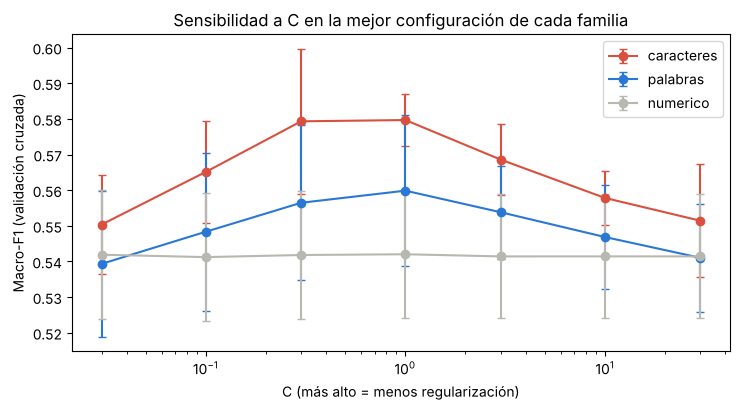

In [4]:
mejor = H.mejores_por_familia(res)
display(mejor.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
colores = {"palabras": AZUL, "caracteres": ROJO, "numerico": GRIS}
for _, f in mejor.iterrows():
    s = res[(res.familia == f.familia) & (res.ngram_range == f.ngram_range) & (res.min_df.astype(str) == str(f.min_df)) & (res.class_weight == f.class_weight)].sort_values("C")
    ax.errorbar(s.C, s.macro_f1_cv, yerr=s.desv_cv, marker="o", capsize=3, label=f.familia, color=colores[f.familia])
ax.set_xscale("log"); ax.set_xlabel("C (más alto = menos regularización)"); ax.set_ylabel("Macro-F1 (validación cruzada)")
ax.set_title("Sensibilidad a C en la mejor configuración de cada familia"); ax.legend(); plt.tight_layout(); plt.show()

In [5]:
for fam, g in res.groupby("familia"):
    print(f"{fam:11s} mejor {g.macro_f1_cv.max():.4f} | peor {g.macro_f1_cv.min():.4f} | mediana {g.macro_f1_cv.median():.4f}")

caracteres  mejor 0.5797 | peor 0.3474 | mediana 0.5569
numerico    mejor 0.5420 | peor 0.5358 | mediana 0.5390
palabras    mejor 0.5599 | peor 0.1899 | mediana 0.5412


Lo que se ve en esta parte:

C es lo que más mueve el resultado, sobre todo en los extremos. Con C muy bajo y sin balancear las clases, el modelo de palabras casi no aprende y cae hasta 0,19, que es el piso de la clase mayoritaria. Con las clases balanceadas el rango es mucho menor: en la mejor configuración de palabras va de 0,54 (C = 0,03) a 0,556 (C entre 0,3 y 1), y baja otra vez con C alto por sobreajuste.

Los n-gramas y `min_df` casi no importan dentro de una misma familia: con C = 1 y balanceado, palabras queda entre 0,550 y 0,560. Lo que sí cambia es la familia, porque caracteres queda por encima de palabras.

Además, las mejores configuraciones se diferencian menos que la desviación entre pliegues (entre 0,01 y 0,02). Que una quede primera en validación cruzada no quiere decir que sea mejor, y eso se revisa en la sección siguiente.

## 4 · Una sola medición en dev

Se reajusta con todo train la mejor configuración de cada familia y se mide en dev, junto a la de referencia del experimento baseline (TF-IDF de palabras (1,2), `min_df` 2, C = 1, balanceado). Las diferencias son pareadas, sobre los mismos tuits, con IC 95% por bootstrap.

In [6]:
resultados, difs, preds = H.evaluar_en_dev(train, dev, res)
display(resultados[resultados.ambito == "Todas"][["modelo", "n_dev", "accuracy", "macro_f1", "ic_inf", "ic_sup"]])
display(difs[difs.ambito == "Todas"][["variante", "predicciones_distintas", "variante_acierta_y_base_no", "base_acierta_y_variante_no", "dif_macro_f1", "ic_inf", "ic_sup", "conclusion"]])

,modelo,n_dev,accuracy,macro_f1,ic_inf,ic_sup
0,referencia,2465,0.5615,0.5556,0.5361,0.5755
6,mejor_caracteres,2465,0.5712,0.5678,0.5482,0.5869
12,mejor_palabras,2465,0.5635,0.5576,0.5375,0.5778
18,mejor_numerico,2465,0.5120,0.5085,0.4888,0.5286


,variante,predicciones_distintas,variante_acierta_y_base_no,base_acierta_y_variante_no,dif_macro_f1,ic_inf,ic_sup,conclusion
0,mejor_caracteres,669,281,257,0.0122,-0.0062,0.0319,no se distingue
6,mejor_palabras,89,37,32,0.0019,-0.0049,0.0085,no se distingue
12,mejor_numerico,926,315,437,-0.0472,-0.0683,-0.0246,A mejor


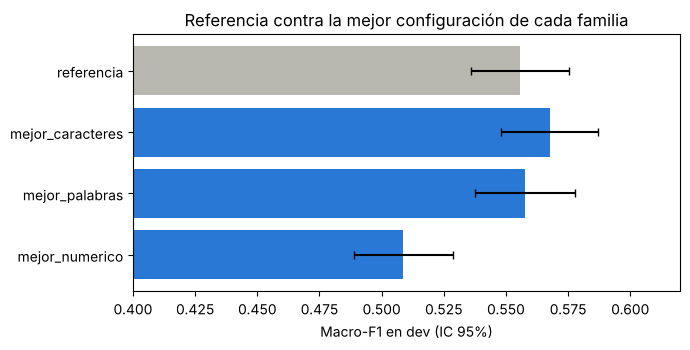

In [7]:
t = resultados[resultados.ambito == "Todas"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(t.modelo, t.macro_f1, xerr=[t.macro_f1 - t.ic_inf, t.ic_sup - t.macro_f1], color=[GRIS if m == "referencia" else AZUL for m in t.modelo], capsize=3)
ax.set_xlim(0.4, 0.62); ax.invert_yaxis(); ax.set_xlabel("Macro-F1 en dev (IC 95%)")
ax.set_title("Referencia contra la mejor configuración de cada familia"); plt.tight_layout(); plt.show()

In [8]:
d = difs[difs.variante == "mejor_caracteres"][["ambito", "dif_macro_f1", "ic_inf", "ic_sup", "conclusion"]]
d

,ambito,dif_macro_f1,ic_inf,ic_sup,conclusion
0,Todas,0.0122,-0.0062,0.0319,no se distingue
1,CR,0.0078,-0.0369,0.0521,no se distingue
2,ES,-0.0009,-0.0394,0.0375,no se distingue
3,MX,-0.0070,-0.0487,0.0347,no se distingue
4,PE,0.0228,-0.0187,0.0645,no se distingue
5,UY,0.0379,-0.0036,0.0784,no se distingue


Optimizar casi no cambia nada. La configuración original ya estaba cerca del techo: con caracteres el Macro-F1 sube alrededor de 0,01 y con palabras alrededor de 0,002, y en los dos casos el intervalo pareado incluye el cero. No se puede afirmar que las configuraciones nuevas sean mejores.

Por variedad pasa lo mismo, ninguna diferencia se separa de cero. Con 390 a 581 tuits por variedad solo se detectarían diferencias de 5 a 6 puntos, así que tampoco era de esperar.

El modelo de 24 variables queda como estaba: su mejor configuración es la que ya se usaba (C = 1, balanceado), y sigue por debajo de las dos representaciones de texto.

Para la tesis, esto significa que el piso clásico está en unos 0,56 a 0,57 de Macro-F1 y no hay una versión afinada mucho mejor que lo contradiga. La comparación con el LLM se mantiene como estaba.

## 5 · Comprobación contra las tablas del repositorio

Lo recalculado aquí debe coincidir con `docs/hiperparametros/tablas/`.

In [9]:
def igual(nuevo, nombre, claves, cols, atol=1e-4):
    g = pd.read_csv(TABLAS / f"{nombre}.csv").set_index(claves).sort_index()
    n = nuevo.set_index(claves).sort_index().loc[g.index]
    return bool(np.allclose(n[cols].to_numpy(float), g[cols].to_numpy(float), atol=atol))

claves_cv = ["familia", "ngram_range", "min_df", "C", "class_weight"]
res_n = res.assign(min_df=res.min_df.astype(str), ngram_range=res.ngram_range.astype(str))
g_cv = pd.read_csv(TABLAS / "busqueda_cv.csv").assign(min_df=lambda d: d.min_df.astype(str))
g_cv["min_df"] = g_cv["min_df"].str.replace(".0", "", regex=False)
res_n["min_df"] = res_n["min_df"].str.replace(".0", "", regex=False)
ok_cv = bool(np.allclose(res_n.set_index(claves_cv).sort_index()["macro_f1_cv"].to_numpy(float), g_cv.set_index(claves_cv).sort_index()["macro_f1_cv"].to_numpy(float), atol=1e-3))
ok_dev = igual(resultados, "resultados_dev", ["modelo", "ambito"], ["macro_f1"])
ok_dif = igual(difs, "diferencias_contra_referencia", ["variante", "ambito"], ["dif_macro_f1"])
print("busqueda_cv                    coincide:", ok_cv)
print("resultados_dev                 coincide:", ok_dev)
print("diferencias_contra_referencia  coincide:", ok_dif)

busqueda_cv                    coincide: True
resultados_dev                 coincide: True
diferencias_contra_referencia  coincide: True


## 6 · Y los hiperparámetros del LLM

No se optimizan, se fijan y se dejan documentados. Para Salamandra-7B-Instruct queda así:

| Parámetro | Valor | Motivo |
| --- | --- | --- |
| Modelo | Salamandra-7B-Instruct, revisión fija, 4 bits | el mismo en monoagente y multiagente, para que la única diferencia sea la arquitectura |
| Decodificación | determinista, sin muestreo | las mismas entradas dan las mismas salidas, y la comparación pareada se puede reproducir |
| Salida | POS, NEG o NEU; lo inválido se cuenta aparte | se reporta el porcentaje de salidas inválidas |
| Datos | el tuit como lo ve el LLM (variante base) | las variantes de limpieza no cambiaron el Macro-F1 |

Lo único que admite ajuste es el prompt, y sería selección de configuración, no entrenamiento. Si se hace, el protocolo es el mismo de este cuaderno: probar las variantes de prompt sobre una submuestra de train (nunca de dev), elegir una y medir dev una sola vez. Eso necesita GPU (Colab) y no se corrió aquí.

## Conclusiones

Se recorrieron 182 configuraciones del baseline clásico con validación cruzada en train, y dev se midió una sola vez. El resultado es más bien que no hay mucho que ganar: C es lo que más pesa, y los caracteres (2,5) quedan primeros en validación cruzada, pero su ventaja en dev (alrededor de +0,01) no se distingue del ruido.

El piso clásico queda en unos 0,56 a 0,57 de Macro-F1. Como optimizar no lo mueve de forma apreciable, el baseline original ya era una referencia justa para comparar con el LLM.

El LLM no tiene hiperparámetros de entrenamiento y su configuración está fija. Lo único que se podría ajustar es el prompt, y se haría solo con train.

## Límites

La búsqueda es una malla acotada: no se probaron otros clasificadores (SVM, árboles) ni otros pesos de clase. Las configuraciones de arriba están dentro de la variación entre pliegues, así que la mejor es en la práctica un empate. Todo se mide en dev porque no existe partición de prueba, y por eso no hay una estimación final sin tocar. Y esto es el baseline clásico, no el LLM.